# Dengue no Brasil (2000–2026): análise exploratória

**Autor:** Marcelo de Moura Maia Júnior · **Instituição:** Centro Universitário La Salle do Rio de Janeiro (Unilasalle-RJ)
**Curso:** Bacharelado em Sistemas de Informação — 6º período · **Disciplina:** Linguagens de Programação (Análise e Visualização de Dados com Python) — 2026.2

Este notebook explora as tabelas geradas por `src/etl.py` a partir das notificações de dengue do SINAN e da população residente do IBGE. A análise é organizada em torno de três perguntas de pesquisa:

- **RQ1 — Tempo:** como a incidência de dengue evoluiu entre 2000 e 2026, qual é o padrão sazonal ao longo do ano e em que medida a epidemia de 2024 se afasta do comportamento histórico?
- **RQ2 — Espaço:** como os casos se distribuem entre regiões, estados e municípios, quão concentrada é essa distribuição e houve expansão para áreas antes pouco afetadas, como a Região Sul?
- **RQ3 — Pessoas e gravidade:** como idade e sexo se relacionam com a ocorrência, a hospitalização, a gravidade e o óbito, e quais sorotipos do vírus circularam no período?

**Como executar:** a partir da raiz do repositório, depois de `python -m src.download` e `python -m src.etl`, abra este notebook com `jupyter notebook notebooks/analise_exploratoria.ipynb`. As figuras são exportadas para `docs/assets/`.

## 0. Preparação e qualidade dos dados

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
from matplotlib.colors import LogNorm
from plotly.subplots import make_subplots
from scipy import stats

from src import config, metricas, populacao
from src import visualizacao as viz

viz.configurar_matplotlib()
viz.configurar_plotly()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda valor: viz.formatar_numero(valor, 2))

ANOS_COMPLETOS = [ano for ano in config.YEARS if ano not in config.PARTIAL_YEARS]
metricas_artigo = {}

In [2]:
NOMES_TABELAS = [
    "casos_semana_uf",
    "casos_ano_uf",
    "casos_ano_municipio",
    "perfil_demografico",
    "casos_raca_cor",
    "sorotipos",
    "completude",
]
tabelas = {nome: pd.read_parquet(config.PROCESSED_DIR / f"{nome}.parquet") for nome in NOMES_TABELAS}
log_etl = pd.read_csv(config.PROCESSED_DIR / "etl_log.csv")
estados = populacao.load_states()
pop_uf = populacao.load_population("uf").rename(columns={"ano": "ano_epi"})
pop_municipio = populacao.load_population("municipio").rename(columns={"ano": "ano_epi"})

pd.DataFrame(
    {
        "linhas": {nome: len(tabela) for nome, tabela in tabelas.items()},
        "colunas": {nome: tabela.shape[1] for nome, tabela in tabelas.items()},
    }
)

,linhas,colunas
casos_semana_uf,36665,11
casos_ano_uf,728,17
casos_ano_municipio,106572,15
perfil_demografico,20995,10
casos_raca_cor,161,8
sorotipos,1436,4
completude,27,10


### 0.1 Rastreabilidade do tratamento

O registro `etl_log.csv` contabiliza, para cada arquivo anual do SINAN, quantas linhas foram lidas, removidas (e por qual motivo) e mantidas. A soma abaixo reconcilia os 27 arquivos brutos com as tabelas analíticas: nenhuma linha some sem justificativa.

In [3]:
colunas_fluxo = [
    "registros_lidos",
    "removidos_duplicidade",
    "removidos_descartados",
    "removidos_chikungunya",
    "removidos_sem_data",
    "casos_provaveis",
    "fora_do_periodo",
    "casos_no_periodo",
]
fluxo = log_etl[colunas_fluxo].sum()
assert fluxo["registros_lidos"] - fluxo[[c for c in colunas_fluxo if c.startswith("removidos")]].sum() == fluxo["casos_provaveis"]
assert fluxo["casos_provaveis"] - fluxo["fora_do_periodo"] == fluxo["casos_no_periodo"]
assert tabelas["completude"]["registros"].sum() == fluxo["casos_no_periodo"]

sem_uf = fluxo["casos_no_periodo"] - tabelas["casos_ano_uf"]["casos"].sum()
fluxo_formatado = fluxo.map(viz.formatar_numero).to_frame("registros")
fluxo_formatado.loc["sem_uf_de_residencia_valida"] = viz.formatar_numero(sem_uf)
metricas_artigo["registros_lidos"] = int(fluxo["registros_lidos"])
metricas_artigo["casos_provaveis_periodo"] = int(fluxo["casos_no_periodo"])
metricas_artigo["removidos_descartados"] = int(fluxo["removidos_descartados"])
metricas_artigo["removidos_duplicidade"] = int(fluxo["removidos_duplicidade"])
fluxo_formatado

,registros
registros_lidos,32.512.002
removidos_duplicidade,430
removidos_descartados,6.146.531
removidos_chikungunya,0
removidos_sem_data,0
casos_provaveis,26.365.041
fora_do_periodo,102
casos_no_periodo,26.364.939
sem_uf_de_residencia_valida,3.860


In [4]:
log_etl[["ano_arquivo", "registros_lidos", "removidos_descartados", "casos_provaveis", "dt_sintomas_imputada", "semana_divergente", "idade_ausente"]]

,ano_arquivo,registros_lidos,removidos_descartados,casos_provaveis,dt_sintomas_imputada,semana_divergente,idade_ausente
0,2000,172855,36131,136724,12,815,114
1,2001,488590,101584,387006,100,201,2176
2,2002,897093,193604,703489,819,2715,5125
3,2003,416609,137309,279300,763,2165,1534
4,2004,136867,64493,72374,220,418,58
5,2005,261501,110355,151146,435,2095,1282
6,2006,411022,144466,266556,702,5375,1184
7,2007,717097,216505,500581,267,270,31
8,2008,919324,281657,637652,1627,2,334
9,2009,600658,189121,411199,1402,0,2


Dois pontos chamam atenção no registro:

- **Casos descartados:** de 2014 a 2015 e de 2022 a 2026 os arquivos publicados já vêm sem os casos descartados (a coluna de removidos é zero). Por isso a análise usa sempre **casos prováveis** (todos os notificados, exceto os descartados), a definição adotada pelo Ministério da Saúde, que é comparável entre todos os anos.
- **Semana epidemiológica:** a semana calculada a partir da data dos sintomas coincide com a semana gravada pelo SINAN em mais de 99% dos registros; as divergências se concentram nos arquivos antigos, anteriores a 2014.

### 0.2 Completude dos campos

A qualidade do preenchimento muda muito ao longo de 27 anos. Campos com baixa completude em um período não podem sustentar comparações naquele período.

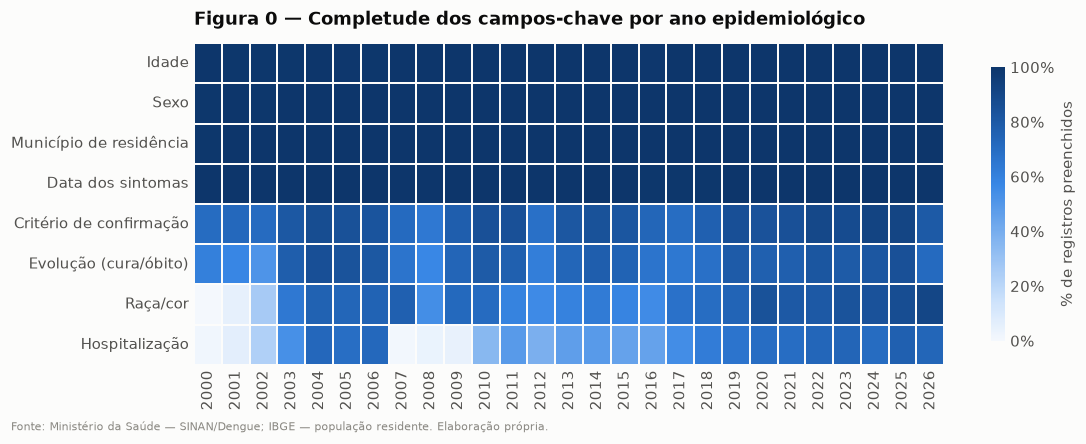

In [5]:
completude = tabelas["completude"].set_index("ano_epi")
rotulos_campos = {
    "pct_idade": "Idade",
    "pct_sexo": "Sexo",
    "pct_municipio_residencia": "Município de residência",
    "pct_dt_sintomas_original": "Data dos sintomas",
    "pct_criterio": "Critério de confirmação",
    "pct_evolucao": "Evolução (cura/óbito)",
    "pct_raca": "Raça/cor",
    "pct_hospitalizacao": "Hospitalização",
}
matriz_completude = completude[list(rotulos_campos)].rename(columns=rotulos_campos).T

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(
    matriz_completude,
    cmap=viz.MAPA_SEQUENCIAL,
    vmin=0,
    vmax=100,
    linewidths=1,
    linecolor=viz.SUPERFICIE,
    cbar_kws={"label": "% de registros preenchidos", "format": viz.EIXO_PERCENTUAL, "shrink": 0.85},
    ax=ax,
)
ax.set_title("Figura 0 — Completude dos campos-chave por ano epidemiológico")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=90)
ax.grid(False)
viz.salvar_figura(fig, "fig00_completude")
plt.show()

In [6]:
matriz_completude.loc[:, [2000, 2003, 2009, 2014, 2019, 2024, 2025]]

ano_epi,2000,2003,2009,2014,2019,2024,2025
Idade,"99,92","99,45","100,00","99,98","99,97","99,99","100,00"
Sexo,"99,60","99,96","99,98","99,84","99,87","99,85","99,93"
Município de residência,"99,56","99,94","99,99","99,99","100,00","100,00","100,00"
Data dos sintomas,"99,99","99,73","99,67","100,00","99,73","100,00","100,00"
Critério de confirmação,"70,65","80,76","77,66","84,24","85,32","92,18","91,15"
Evolução (cura/óbito),"60,58","77,98","74,12","77,45","79,21","81,42","84,84"
Raça/cor,"0,26","64,07","72,26","63,17","74,31","83,82","86,65"
Hospitalização,"1,78","53,38","4,30","48,67","66,08","70,64","76,20"


Idade, sexo, município e data dos sintomas estão praticamente completos em todo o período e sustentam a análise temporal, geográfica e demográfica. **Hospitalização** só passa de 30% de preenchimento a partir de 2010 e **raça/cor** oscila entre 55% e 90%; por isso, as proporções de hospitalização usam como denominador apenas os registros com o campo preenchido, e a análise de perfil (RQ3) se restringe a 2014–2025, período com a classificação de casos atual e preenchimento mais estável.

## 1. RQ1 — Evolução temporal e sazonalidade

In [7]:
anual = (
    tabelas["casos_ano_uf"]
    .groupby("ano_epi")[["casos", "casos_graves", "obitos", "populacao"]]
    .sum()
    .rename(columns={"populacao": "populacao_uf"})
)
anual["populacao"] = pop_uf.groupby("ano_epi")["populacao"].sum()
anual["incidencia"] = metricas.incidencia(anual["casos"], anual["populacao"])
anual["parcial"] = anual.index.isin(config.PARTIAL_YEARS)
anual[["casos", "obitos", "populacao", "incidencia", "parcial"]]

,casos,obitos,populacao,incidencia,parcial
ano_epi,,,,,
2000,136824,36,169872859,"80,54",False
2001,388560,154,172385826,"225,40",False
2002,701262,330,174632960,"401,56",False
2003,279455,195,176871437,"158,00",False
2004,72309,46,181569056,"39,82",False
2005,151344,141,184184264,"82,17",False
2006,267553,253,186770562,"143,25",False
2007,500771,327,188187786,"266,10",False
2008,638192,582,189605006,"336,59",False


In [8]:
incidencia_completa = anual.loc[ANOS_COMPLETOS, "incidencia"]
resumo_anual = metricas.resumo_descritivo(incidencia_completa)
resumo_anual.to_frame("incidência anual (por 100 mil)")

,incidência anual (por 100 mil)
n,"26,00"
media,"490,11"
mediana,"323,01"
desvio_padrao,"588,18"
coef_variacao,"1,20"
minimo,"39,82"
q1,"173,43"
q3,"715,92"
maximo,"3.088,17"
assimetria,"3,66"


In [9]:
atipicos = pd.DataFrame(
    {
        "incidencia": incidencia_completa,
        "escore_robusto": metricas.escore_robusto(incidencia_completa),
        "atipico_iqr": metricas.atipicos_iqr(incidencia_completa),
        "atipico_robusto": metricas.atipicos_robustos(incidencia_completa),
    }
)
maior_anterior = incidencia_completa.loc[: 2023].max()
ano_maior_anterior = int(incidencia_completa.loc[: 2023].idxmax())
razao_2024 = incidencia_completa[2024] / maior_anterior

metricas_artigo.update(
    {
        "casos_2024": int(anual.loc[2024, "casos"]),
        "incidencia_2024": round(float(anual.loc[2024, "incidencia"]), 1),
        "obitos_2024": int(anual.loc[2024, "obitos"]),
        "maior_incidencia_anterior": round(float(maior_anterior), 1),
        "ano_maior_incidencia_anterior": ano_maior_anterior,
        "razao_2024_recorde_anterior": round(float(razao_2024), 2),
        "incidencia_mediana_anual": round(float(resumo_anual["mediana"]), 1),
        "coef_variacao_incidencia_anual": round(float(resumo_anual["coef_variacao"]), 2),
        "escore_robusto_2024": round(float(atipicos.loc[2024, "escore_robusto"]), 1),
    }
)
print(f"2024: {viz.formatar_numero(incidencia_completa[2024], 1)} casos por 100 mil — "
      f"{viz.formatar_numero(razao_2024, 1)} vezes o maior valor anterior ({ano_maior_anterior}).")
atipicos.sort_values("escore_robusto", ascending=False).head(6)

2024: 3.088,2 casos por 100 mil — 3,8 vezes o maior valor anterior (2015).


,incidencia,escore_robusto,atipico_iqr,atipico_robusto
ano_epi,,,,
2024,"3.088,17","9,31",True,True
2015,"806,20","1,63",False,False
2023,"791,95","1,58",False,False
2025,"769,68","1,50",False,False
2019,"740,15","1,40",False,False
2013,"729,59","1,37",False,False


A incidência anual tem distribuição fortemente assimétrica: a mediana fica em torno de 300 casos por 100 mil habitantes, mas o desvio-padrão é maior que a média (coeficiente de variação acima de 1). Pelos dois critérios de valor atípico — a regra do intervalo interquartil (Tukey) e o escore-z modificado baseado na mediana (Iglewicz e Hoaglin), que não é distorcido pelos próprios extremos — **2024 é o único ano atípico**, com incidência quase quatro vezes maior que o recorde anterior, de 2015.

In [10]:
cores_barras = [viz.NEUTRO if parcial else viz.CATEGORICA[0] for parcial in anual["parcial"]]
fig = go.Figure(
    go.Bar(
        x=anual.index,
        y=anual["incidencia"],
        marker={"color": cores_barras, "line": {"width": 0}},
        customdata=np.column_stack([anual["casos"], anual["obitos"]]),
        hovertemplate=(
            "<b>%{x}</b><br>Incidência: %{y:,.1f} por 100 mil hab.<br>"
            "Casos prováveis: %{customdata[0]:,.0f}<br>Óbitos: %{customdata[1]:,.0f}<extra></extra>"
        ),
    )
)
fig.add_annotation(
    x=2024, y=anual.loc[2024, "incidencia"],
    text=f"<b>{viz.formatar_numero(anual.loc[2024, 'incidencia'], 0)}</b>",
    showarrow=False, yshift=14, font={"size": 12},
)
fig.add_annotation(
    x=2026, y=anual.loc[2026, "incidencia"], text="2026<br>parcial",
    showarrow=False, yshift=22, font={"size": 11, "color": viz.TINTA_SECUNDARIA},
)
fig.update_layout(
    title="Figura 1 — Incidência anual de dengue no Brasil, 2000–2026",
    yaxis={"title": "Casos prováveis por 100 mil habitantes", "tickformat": ",.0f"},
    xaxis={"range": [1999.4, 2026.6], "tickangle": 0},
    bargap=0.25,
    hovermode="closest",
    height=480,
    showlegend=False,
)
viz.salvar_interativo(fig, "fig01_incidencia_anual")
fig.show()

In [11]:
semanal = tabelas["casos_semana_uf"].groupby(["ano_epi", "semana_epi"], as_index=False)["casos"].sum()
semanal = semanal.merge(pop_uf.groupby("ano_epi", as_index=False)["populacao"].sum(), on="ano_epi")
semanal["incidencia"] = metricas.incidencia(semanal["casos"], semanal["populacao"])

quatro_jan = pd.to_datetime(semanal["ano_epi"].astype(str) + "-01-04")
inicio_ano_epi = quatro_jan - pd.to_timedelta((quatro_jan.dt.day_of_week + 1) % 7, unit="D")
semanal["inicio_semana"] = inicio_ano_epi + pd.to_timedelta((semanal["semana_epi"].astype("int64") - 1) * 7, unit="D")
semanal.tail()

,ano_epi,semana_epi,casos,populacao,incidencia,inicio_semana
1391,2026,35,7013,214211951,"3,27",2026-08-30
1392,2026,36,7014,214211951,"3,27",2026-09-06
1393,2026,37,7390,214211951,"3,45",2026-09-13
1394,2026,38,7483,214211951,"3,49",2026-09-20
1395,2026,39,3445,214211951,"1,61",2026-09-27


In [12]:
fig = go.Figure(
    go.Scatter(
        x=semanal["inicio_semana"],
        y=semanal["incidencia"],
        mode="lines",
        line={"color": viz.CATEGORICA[0], "width": 1.6},
        customdata=semanal[["semana_epi", "ano_epi", "casos"]].to_numpy(),
        hovertemplate=(
            "Semana %{customdata[0]} de %{customdata[1]}<br>"
            "Incidência: %{y:,.2f} por 100 mil hab.<br>Casos: %{customdata[2]:,.0f}<extra></extra>"
        ),
    )
)
fig.update_layout(
    title="Figura 2 — Incidência semanal de dengue no Brasil, 2000–2026",
    yaxis_title="Casos prováveis por 100 mil hab. na semana",
    xaxis={"rangeslider": {"visible": True, "thickness": 0.08}, "tickformat": "%Y", "type": "date"},
    hovermode="closest",
    height=520,
    showlegend=False,
)
viz.salvar_interativo(fig, "fig02_incidencia_semanal")
fig.show()

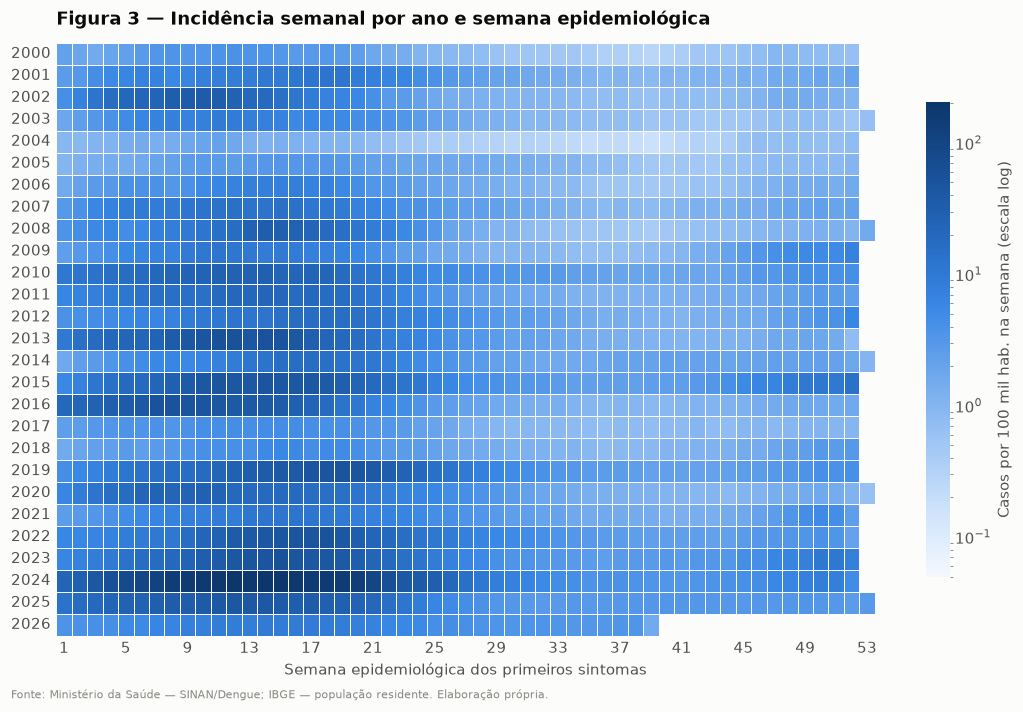

In [13]:
matriz_semanal = semanal.pivot(index="ano_epi", columns="semana_epi", values="incidencia")

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    matriz_semanal,
    cmap=viz.MAPA_SEQUENCIAL,
    norm=LogNorm(vmin=0.05, vmax=matriz_semanal.max().max()),
    linewidths=0.4,
    linecolor=viz.SUPERFICIE,
    cbar_kws={"label": "Casos por 100 mil hab. na semana (escala log)", "shrink": 0.8},
    ax=ax,
)
ax.set_title("Figura 3 — Incidência semanal por ano e semana epidemiológica")
ax.set_xlabel("Semana epidemiológica dos primeiros sintomas")
ax.set_ylabel("")
ax.set_xticks(np.arange(0, 53, 4) + 0.5, labels=range(1, 54, 4), rotation=0)
ax.tick_params(axis="y", rotation=0)
ax.grid(False)
viz.salvar_figura(fig, "fig03_sazonalidade")
plt.show()

In [14]:
completas = semanal[semanal["ano_epi"].isin(ANOS_COMPLETOS)]
picos = completas.loc[completas.groupby("ano_epi")["casos"].idxmax(), ["ano_epi", "semana_epi", "inicio_semana", "incidencia"]]
casos_por_semana = completas.groupby("semana_epi")["casos"].sum()
pct_semanas_8_20 = casos_por_semana.loc[8:20].sum() / casos_por_semana.sum() * 100
pct_primeiro_semestre = casos_por_semana.loc[1:26].sum() / casos_por_semana.sum() * 100

metricas_artigo.update(
    {
        "semana_pico_mediana": int(picos["semana_epi"].median()),
        "semana_pico_min": int(picos["semana_epi"].min()),
        "semana_pico_max": int(picos["semana_epi"].max()),
        "pct_casos_semanas_8_20": round(float(pct_semanas_8_20), 1),
        "pct_casos_semanas_1_26": round(float(pct_primeiro_semestre), 1),
    }
)
print(f"Semana de pico: mediana {int(picos['semana_epi'].median())} "
      f"(entre {picos['semana_epi'].min()} e {picos['semana_epi'].max()}).")
print(f"Casos entre as semanas 8 e 20: {viz.formatar_percentual(pct_semanas_8_20)}; "
      f"no primeiro semestre: {viz.formatar_percentual(pct_primeiro_semestre)}.")
picos.set_index("ano_epi")["semana_epi"].to_frame("semana de pico").T

Semana de pico: mediana 14 (entre 8 e 19).
Casos entre as semanas 8 e 20: 63,3%; no primeiro semestre: 89,0%.


ano_epi,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
semana de pico,12,18,10,11,11,15,16,15,14,11,14,14,16,11,17,14,8,16,15,19,10,14,18,15,12,12


A sazonalidade é marcada e estável: em todos os 26 anos completos o pico ocorre entre o fim do verão e o outono, e cerca de dois terços dos casos se concentram entre as semanas 8 e 20 (aproximadamente de fevereiro a meados de maio), período de chuvas e calor que favorece a reprodução do *Aedes aegypti*. A Figura 3 mostra que a "mancha" sazonal se repete ano a ano, ganhando intensidade nos anos epidêmicos (2002, 2008, 2010, 2013, 2015–2016, 2019, 2022–2025).

### 1.1 Canal endêmico

O canal endêmico é a ferramenta usada pela vigilância epidemiológica para decidir se a incidência de uma semana está acima do esperado. Para cada semana, calculam-se o primeiro quartil, a mediana e o terceiro quartil da incidência nos anos de referência (aqui, 2017 a 2023, os sete anos anteriores à epidemia). Valores acima do terceiro quartil indicam zona de alerta ou epidemia.

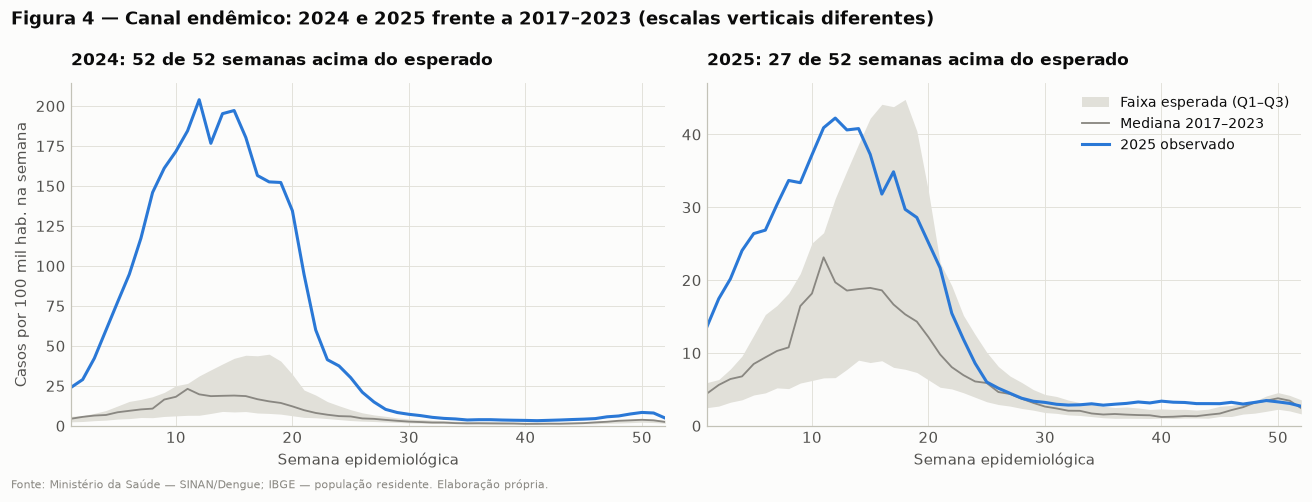

No pico de 2024 (semana 12), a incidência foi 6,5 vezes o terceiro quartil histórico.


In [15]:
ANOS_BASE = list(range(2017, 2024))
canal = metricas.canal_endemico(semanal, ANOS_BASE)
anos_comparados = [2024, 2025]

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, ano in zip(eixos, anos_comparados, strict=True):
    observado = semanal[(semanal["ano_epi"] == ano) & (semanal["semana_epi"] <= 52)].set_index("semana_epi")["incidencia"]
    ax.fill_between(canal.index, canal["q1"], canal["q3"], color=viz.GRADE, linewidth=0, label="Faixa esperada (Q1–Q3)")
    ax.plot(canal.index, canal["mediana"], color=viz.TINTA_SUAVE, linewidth=1.2, label="Mediana 2017–2023")
    ax.plot(observado.index, observado.values, color=viz.CATEGORICA[0], linewidth=2, label=f"{ano} observado")
    acima = (observado > canal["q3"].reindex(observado.index)).sum()
    ax.set_title(f"{ano}: {acima} de {len(observado)} semanas acima do esperado", fontsize=11)
    ax.set_xlabel("Semana epidemiológica")
    ax.set_xlim(1, 52)
    ax.set_ylim(bottom=0)
    metricas_artigo[f"semanas_acima_q3_{ano}"] = int(acima)
eixos[0].set_ylabel("Casos por 100 mil hab. na semana")
eixos[1].legend(loc="upper right")
fig.suptitle("Figura 4 — Canal endêmico: 2024 e 2025 frente a 2017–2023 (escalas verticais diferentes)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
viz.salvar_figura(fig, "fig04_canal_endemico")
plt.show()

pico_2024 = semanal[semanal["ano_epi"] == 2024].set_index("semana_epi")["incidencia"]
razao_pico = pico_2024.max() / canal.loc[pico_2024.idxmax(), "q3"]
metricas_artigo["razao_pico_2024_q3"] = round(float(razao_pico), 1)
print(f"No pico de 2024 (semana {pico_2024.idxmax()}), a incidência foi {viz.formatar_numero(razao_pico, 1)} vezes o terceiro quartil histórico.")

**Resposta à RQ1.** A dengue no Brasil alterna anos de transmissão moderada com epidemias a cada dois ou três anos, sempre concentradas entre fevereiro e maio. A epidemia de 2024 rompe esse padrão em magnitude, não em época: o pico ocorreu na mesma janela sazonal de sempre, mas no pico a incidência semanal chegou a mais de seis vezes o limite superior do canal endêmico, e todas as semanas do ano ficaram acima da faixa esperada. Em 2025 a incidência voltou a níveis de anos epidêmicos anteriores: ficou acima do esperado no início da temporada, antecipando o pico, e dentro da faixa no restante do ano.